In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded =files.upload()


Saving train.csv to train.csv/train.csv


In [39]:
df=pd.read_csv("train.csv/train.csv")
print(df.to_string())
print(df.head())
df['Profit']=df['Sales'] * 0.30
df['Profit']=df['Profit'].round(2)
print(df[['Sales','Profit']])



      Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID           Customer Name      Segment        Country               City                 State  Postal Code   Region       Product ID         Category Sub-Category                                                                                                                     Product Name       Sales
0          1  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520             Claire Gute     Consumer  United States          Henderson              Kentucky      42420.0    South  FUR-BO-10001798        Furniture    Bookcases                                                                                                Bush Somerset Collection Bookcase    261.9600
1          2  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520             Claire Gute     Consumer  United States          Henderson              Kentucky      42420.0    South  FUR-CH-10000454        Furniture   

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   object        
 2   Order Date     9800 non-null   datetime64[ns]
 3   Ship Date      9800 non-null   datetime64[ns]
 4   Ship Mode      9800 non-null   object        
 5   Customer ID    9800 non-null   object        
 6   Customer Name  9800 non-null   object        
 7   Segment        9800 non-null   object        
 8   Country        9800 non-null   object        
 9   City           9800 non-null   object        
 10  State          9800 non-null   object        
 11  Postal Code    9800 non-null   float64       
 12  Region         9800 non-null   object        
 13  Product ID     9800 non-null   object        
 14  Category       9800 non-null   object        
 15  Sub-Category   9800 n

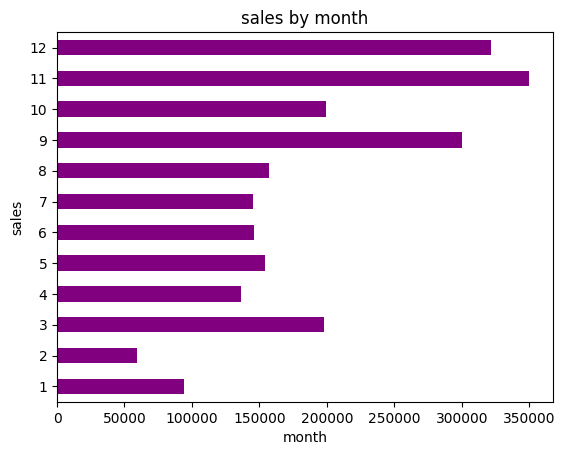

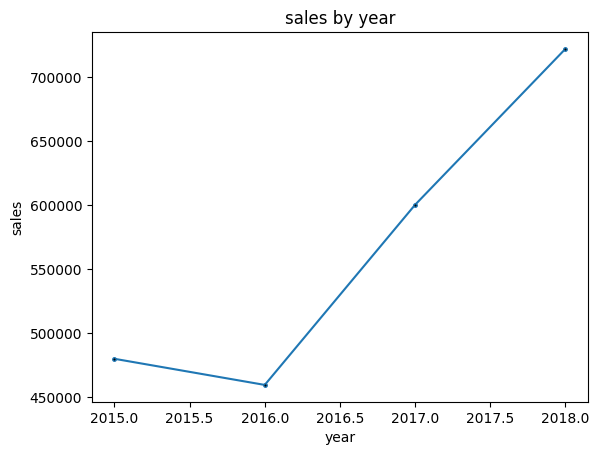

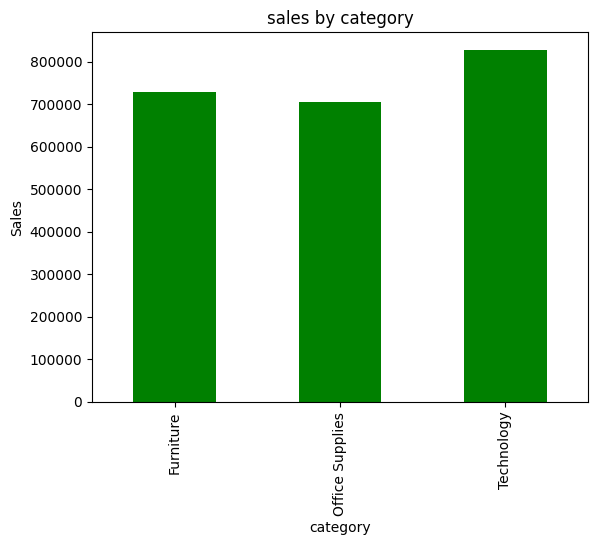

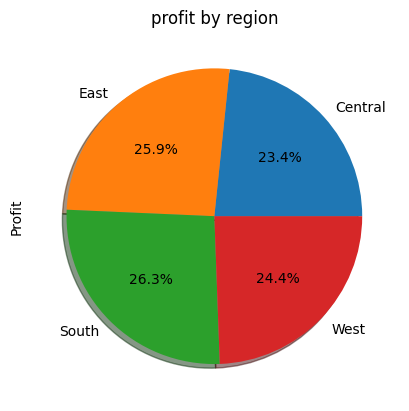

<Axes: xlabel='Region', ylabel='Sales'>

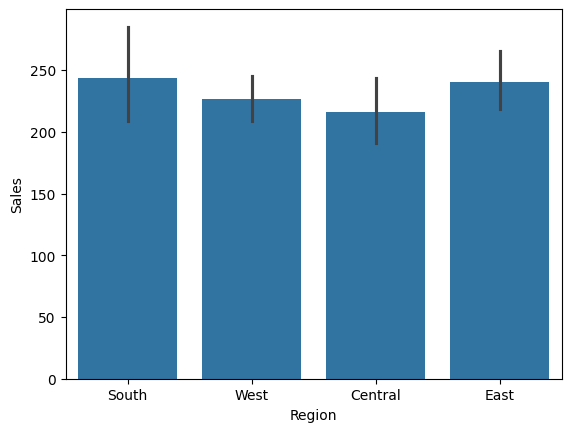

In [72]:
#Data Cleaning
print(df.info())
print(df.drop_duplicates(inplace=True))
df.fillna({'Postal Code': 0},inplace=True)
df['Order Date']=pd.to_datetime(df['Order Date'],dayfirst=True)
df['Ship Date']=pd.to_datetime(df['Ship Date'],dayfirst=True)

print(df[['Order Date','Ship Date']].dtypes)
df['year']=df['Order Date'].dt.year
df['month']=df['Order Date'].dt.month
df['month_year']=df['Order Date'].dt.to_period("M")
print(df.isnull().sum())

#Analysis
print(df.info())
#sales By trend
print("sales By trend")
x=df['Sales'].sum().round(2)
print(x)
#sales by category
print("sales by category")
sales_by_region=df.groupby('Category')["Sales"].sum().round(2)
print(sales_by_region)
#best month for sales
print("best month for sales")
sales_by_month=df.groupby('month')['Sales'].sum().round(2)
print(sales_by_month)
#most profit by region
print("most profit by region")
profit_by_region=df.groupby('Region')['Profit'].mean().round(2)
print(profit_by_region)
#sales by regions
print("sales by regions")
region_by_sales=df.groupby('Region')['Sales'].sum().round(2)
print(region_by_sales)
#year wise sales
print("year wise sales")
print(df.groupby('year')['Sales'].sum().round(2))

#visualization
sales_by_month.plot(kind="barh",color="purple")
plt.xlabel("month")
plt.ylabel("sales")
plt.title("sales by month")
plt.show()

plt.plot(df.groupby('year')['Sales'].sum(),marker='.',markersize=5,markerfacecolor="black")
plt.xlabel("year")
plt.ylabel("sales")
plt.title("sales by year")
plt.show()

sales_by_region.plot(kind="bar",color="green")
plt.xlabel("category")
plt.ylabel('Sales')
plt.title("sales by category")
plt.show()

colors=["pink","yellow","silver","gold","violet"]
profit_by_region.plot(kind="pie",
                      autopct='%1.1f%%',
                      shadow=True,
                      color=colors)
plt.title("profit by region")
plt.show()

sns.barplot(x="Region",y="Sales",data=df)








